# Cuaderno de trabajo · EDA sobre electromovilidad, recarga, CO₂ y NO₂

*Cuaderno complementario para el profesor. No sustituye al notebook original del EDA.*

**Aviso sobre el método.** Este cuaderno reconstruye el proceso de trabajo a partir de los archivos del proyecto (tablas, memoria, presentación y código). No es un registro literal de cada paso que di. Todas las cifras que aparecen aquí se leen de las tablas ya generadas por el proyecto; **no vuelvo a estimar los modelos**. Los dos gráficos comparativos nuevos se generaron con un script aparte (`graficos_comparativos/generar_graficos_comparativos.py`) que reutiliza el código del proyecto sin modificarlo.

Cuando escribo «quise» o «decidí», me refiero a decisiones que aparecen documentadas en la memoria del proyecto.


## 1. Qué quería estudiar

Quería saber si la expansión del coche eléctrico va acompañada de tres cosas que suelen esperarse de ella:

- **Menos CO₂ del transporte** por persona (H1, hipótesis principal).
- **Más coches eléctricos donde hay más cargadores** (H2).
- **Aire más limpio en las ciudades**, medido como NO₂ estimado (H3).

Lo planteé con datos de **61 países**, sin entrar en el detalle de cada ciudad. Son comparaciones **entre países**, así que lo que puedo decir es qué suele ir junto con qué, no qué causa qué.

Las tres hipótesis son:

| Hipótesis | Qué afirma | Año o periodo | Países |
|---|---|---|---|
| H1 | Donde hay más coches eléctricos, el CO₂ del transporte por persona baja más | 2015–2023 | 46 |
| H2 | Donde hay más cargadores públicos por habitante, hay más coches eléctricos | 2024 | 43 |
| H3 | Donde hay más coches eléctricos, el NO₂ urbano estimado es menor | abril–noviembre 2025 | 46 |


## 2. Los datos

Las fuentes son la **IEA** (coches eléctricos, cargadores), el **Banco Mundial** (CO₂ del transporte, PIB por persona, población, urbanización y densidad), **AFIR** (cargadores en la Unión Europea, usado solo para un contraste) y la **Agencia Europea de Medio Ambiente** (NO₂ estimado por área urbana funcional). El detalle de cada fuente está en `ENTREGA_PROFESOR/FUENTES.md`.

Lo primero que me aclaré fue la **unidad de observación**. Cada fila del panel es un **país en un año**. Con 61 países y 16 años (2010–2025) salen 61 × 16 = **976 observaciones país-año**. No son 976 países: es el mismo país repetido en cada año.

Otra idea que tuve que tener clara: **un dato que falta no es un cero**. Un cero afirma que el país no tiene cargadores o coches eléctricos; un hueco significa que no sabemos. Por eso no rellené los huecos: cada análisis usa solo los países que tienen completos los datos que necesita.


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

CARPETA = Path.cwd()
ENTREGA = (CARPETA / ".." / ".." / "ENTREGA_PROFESOR").resolve()
TABLAS = ENTREGA / "src" / "outputs" / "tablas"
PANEL = ENTREGA / "src" / "data" / "procesados" / "panel_pais_anio.csv"
GRAFICOS = CARPETA / "graficos_comparativos"
PRESENTACION = ENTREGA / "src" / "outputs" / "presentacion"

assert TABLAS.exists() and PANEL.exists() and GRAFICOS.exists(), "Revisa la estructura de carpetas"
print("Proyecto:", ENTREGA)


Proyecto: /sessions/rcw-01ehxjvqmqvqxdxyenryqcp7/mnt/Desktop/EDA_REVISION_FINAL/ENTREGA_PROFESOR


In [2]:
panel = pd.read_csv(PANEL)
print("Filas (país-año):", len(panel))
print("Países distintos:", panel["iso3"].nunique())
print("Años:", panel["anio"].min(), "a", panel["anio"].max())
print("Cuota de coches eléctricos con dato:", panel["cuota_parque_pct"].notna().sum())
print("Puntos de recarga con dato:", panel["puntos_recarga_publicos"].notna().sum())


Filas (país-año): 976
Países distintos: 61
Años: 2010 a 2025
Cuota de coches eléctricos con dato: 620
Puntos de recarga con dato: 442


Estos números confirman lo que quería comprobar: 61 países × 16 años = 976 filas, pero solo 620 tienen cuota de coches eléctricos y 442 tienen puntos de recarga. Los huecos se concentran en los primeros años.


In [3]:
huecos = (panel.assign(falta_cuota=panel["cuota_parque_pct"].isna())
          .groupby("anio")["falta_cuota"].sum()
          .rename("países sin cuota de VE"))
display(huecos.to_frame())


,países sin cuota de VE
anio,
2010,39
2011,34
2012,30
2013,27
2014,26
2015,24
2016,23
2017,20
2018,19


Por ejemplo, en 2010 faltan 39 de los 61 países en la cuota, y en 2024 faltan 15. Por eso cada hipótesis trabaja con sus propios países: H1 usa 46, H2 usa 43 y H3 usa 46. Si hubiera rellenado los huecos con ceros, habría afirmado que esos países no tienen coches eléctricos, y no es lo que sabemos.


## 3. Exploración previa

Antes de hacer ningún contraste, quise ver cómo se reparten los coches eléctricos entre países. La presentación del proyecto ya lo muestra con dos figuras (adopción por país y mapa de 2024). Las incluyo aquí como punto de partida.


01_adopcion_paises.png


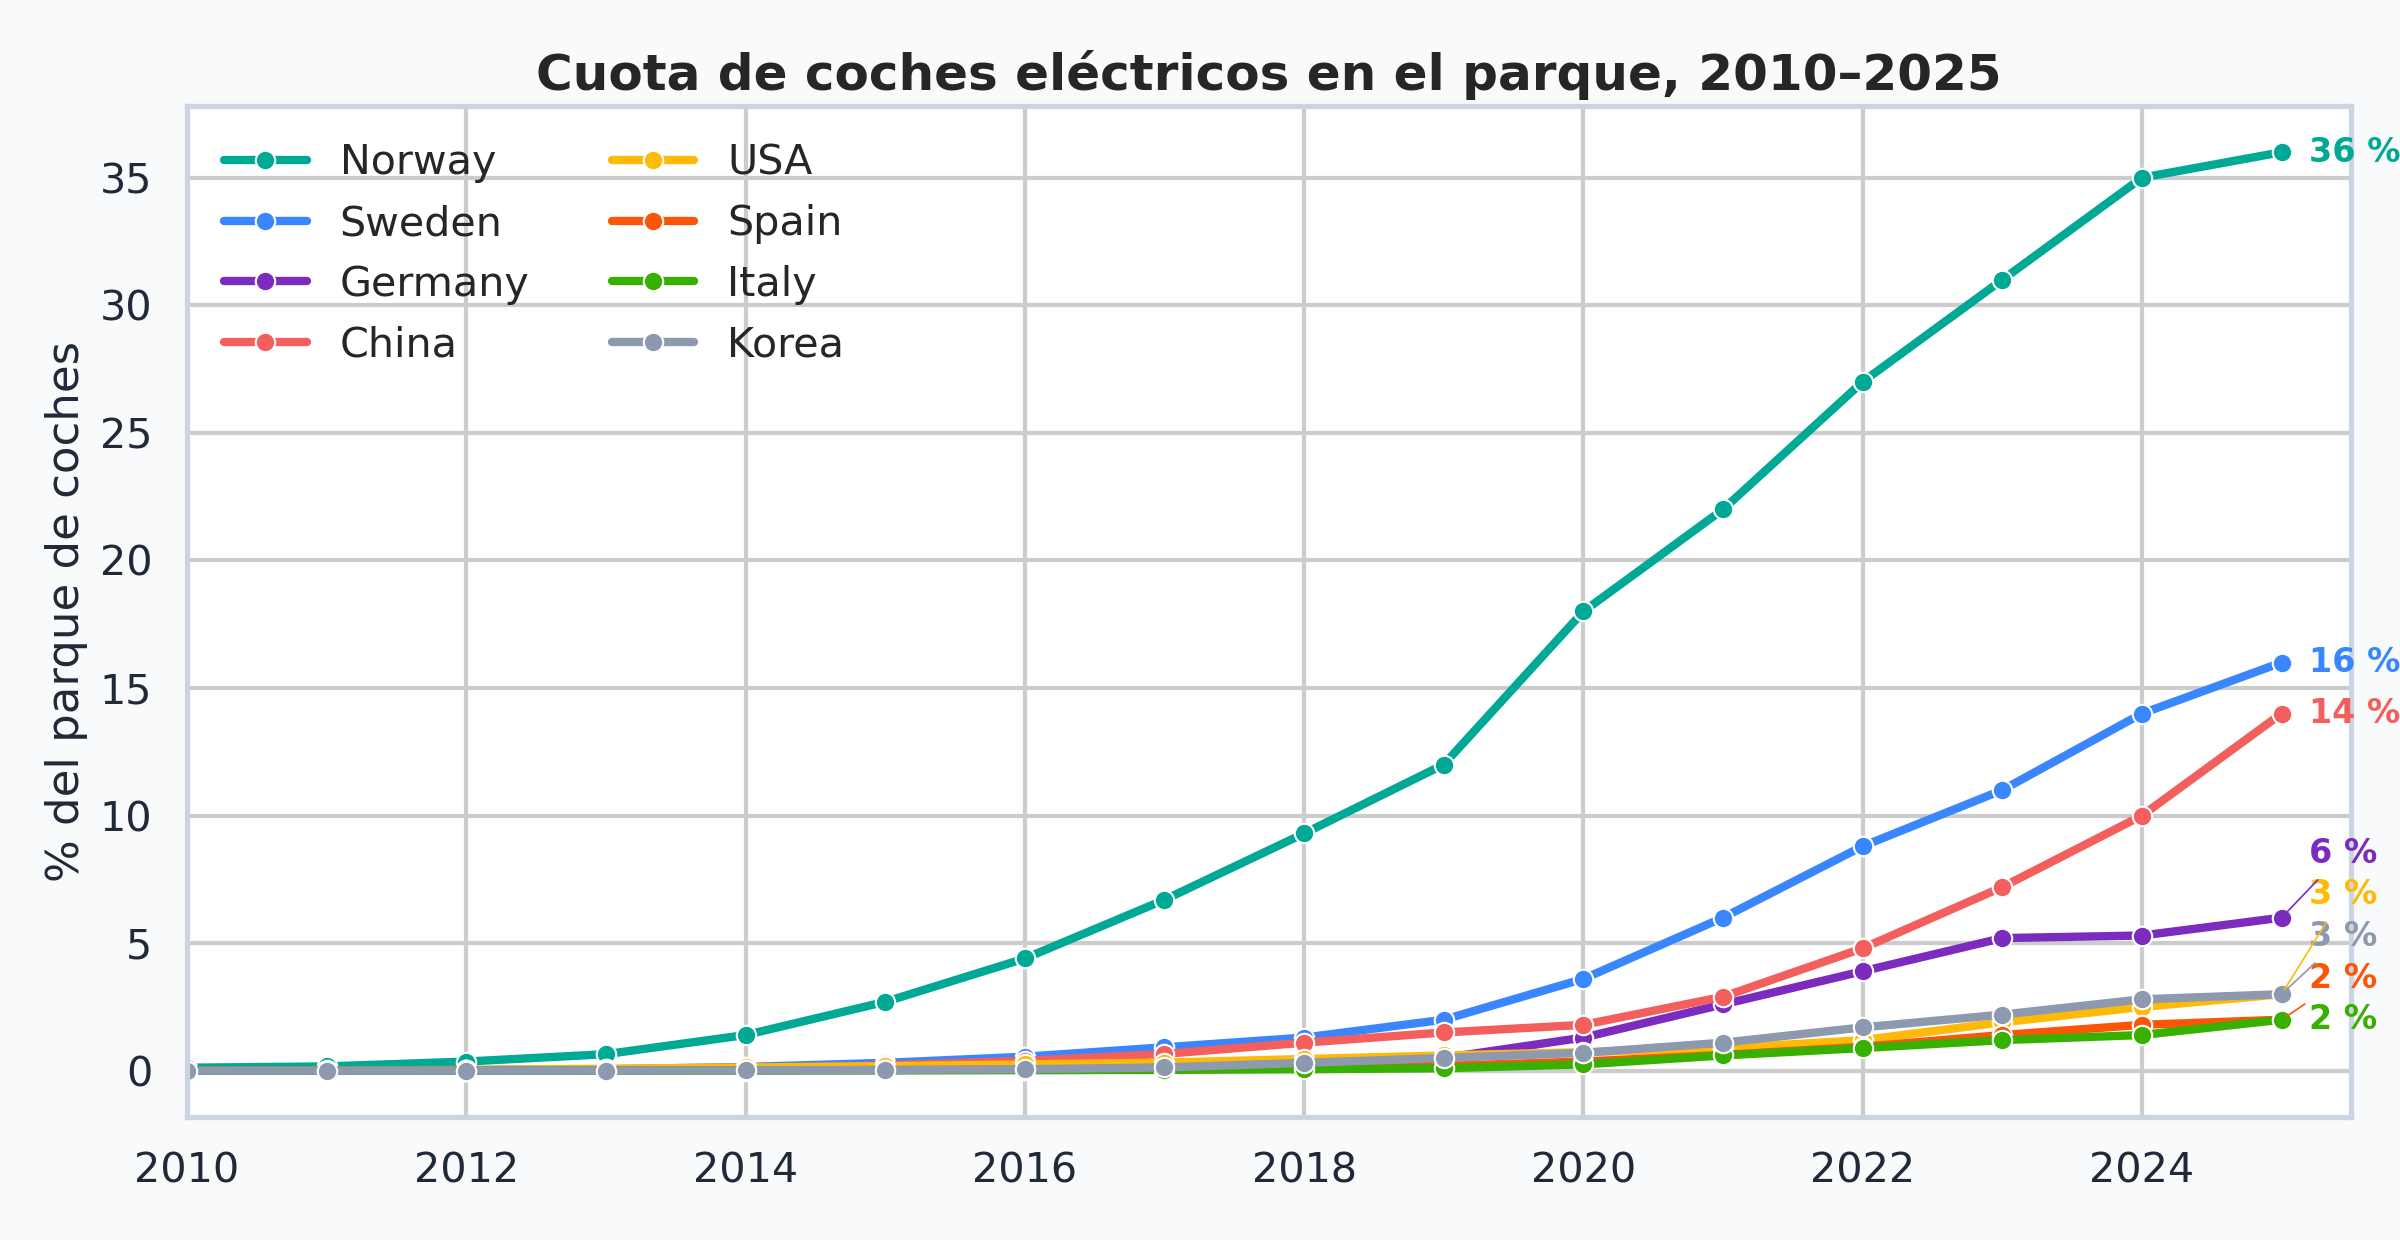

02_mapa_adopcion.png


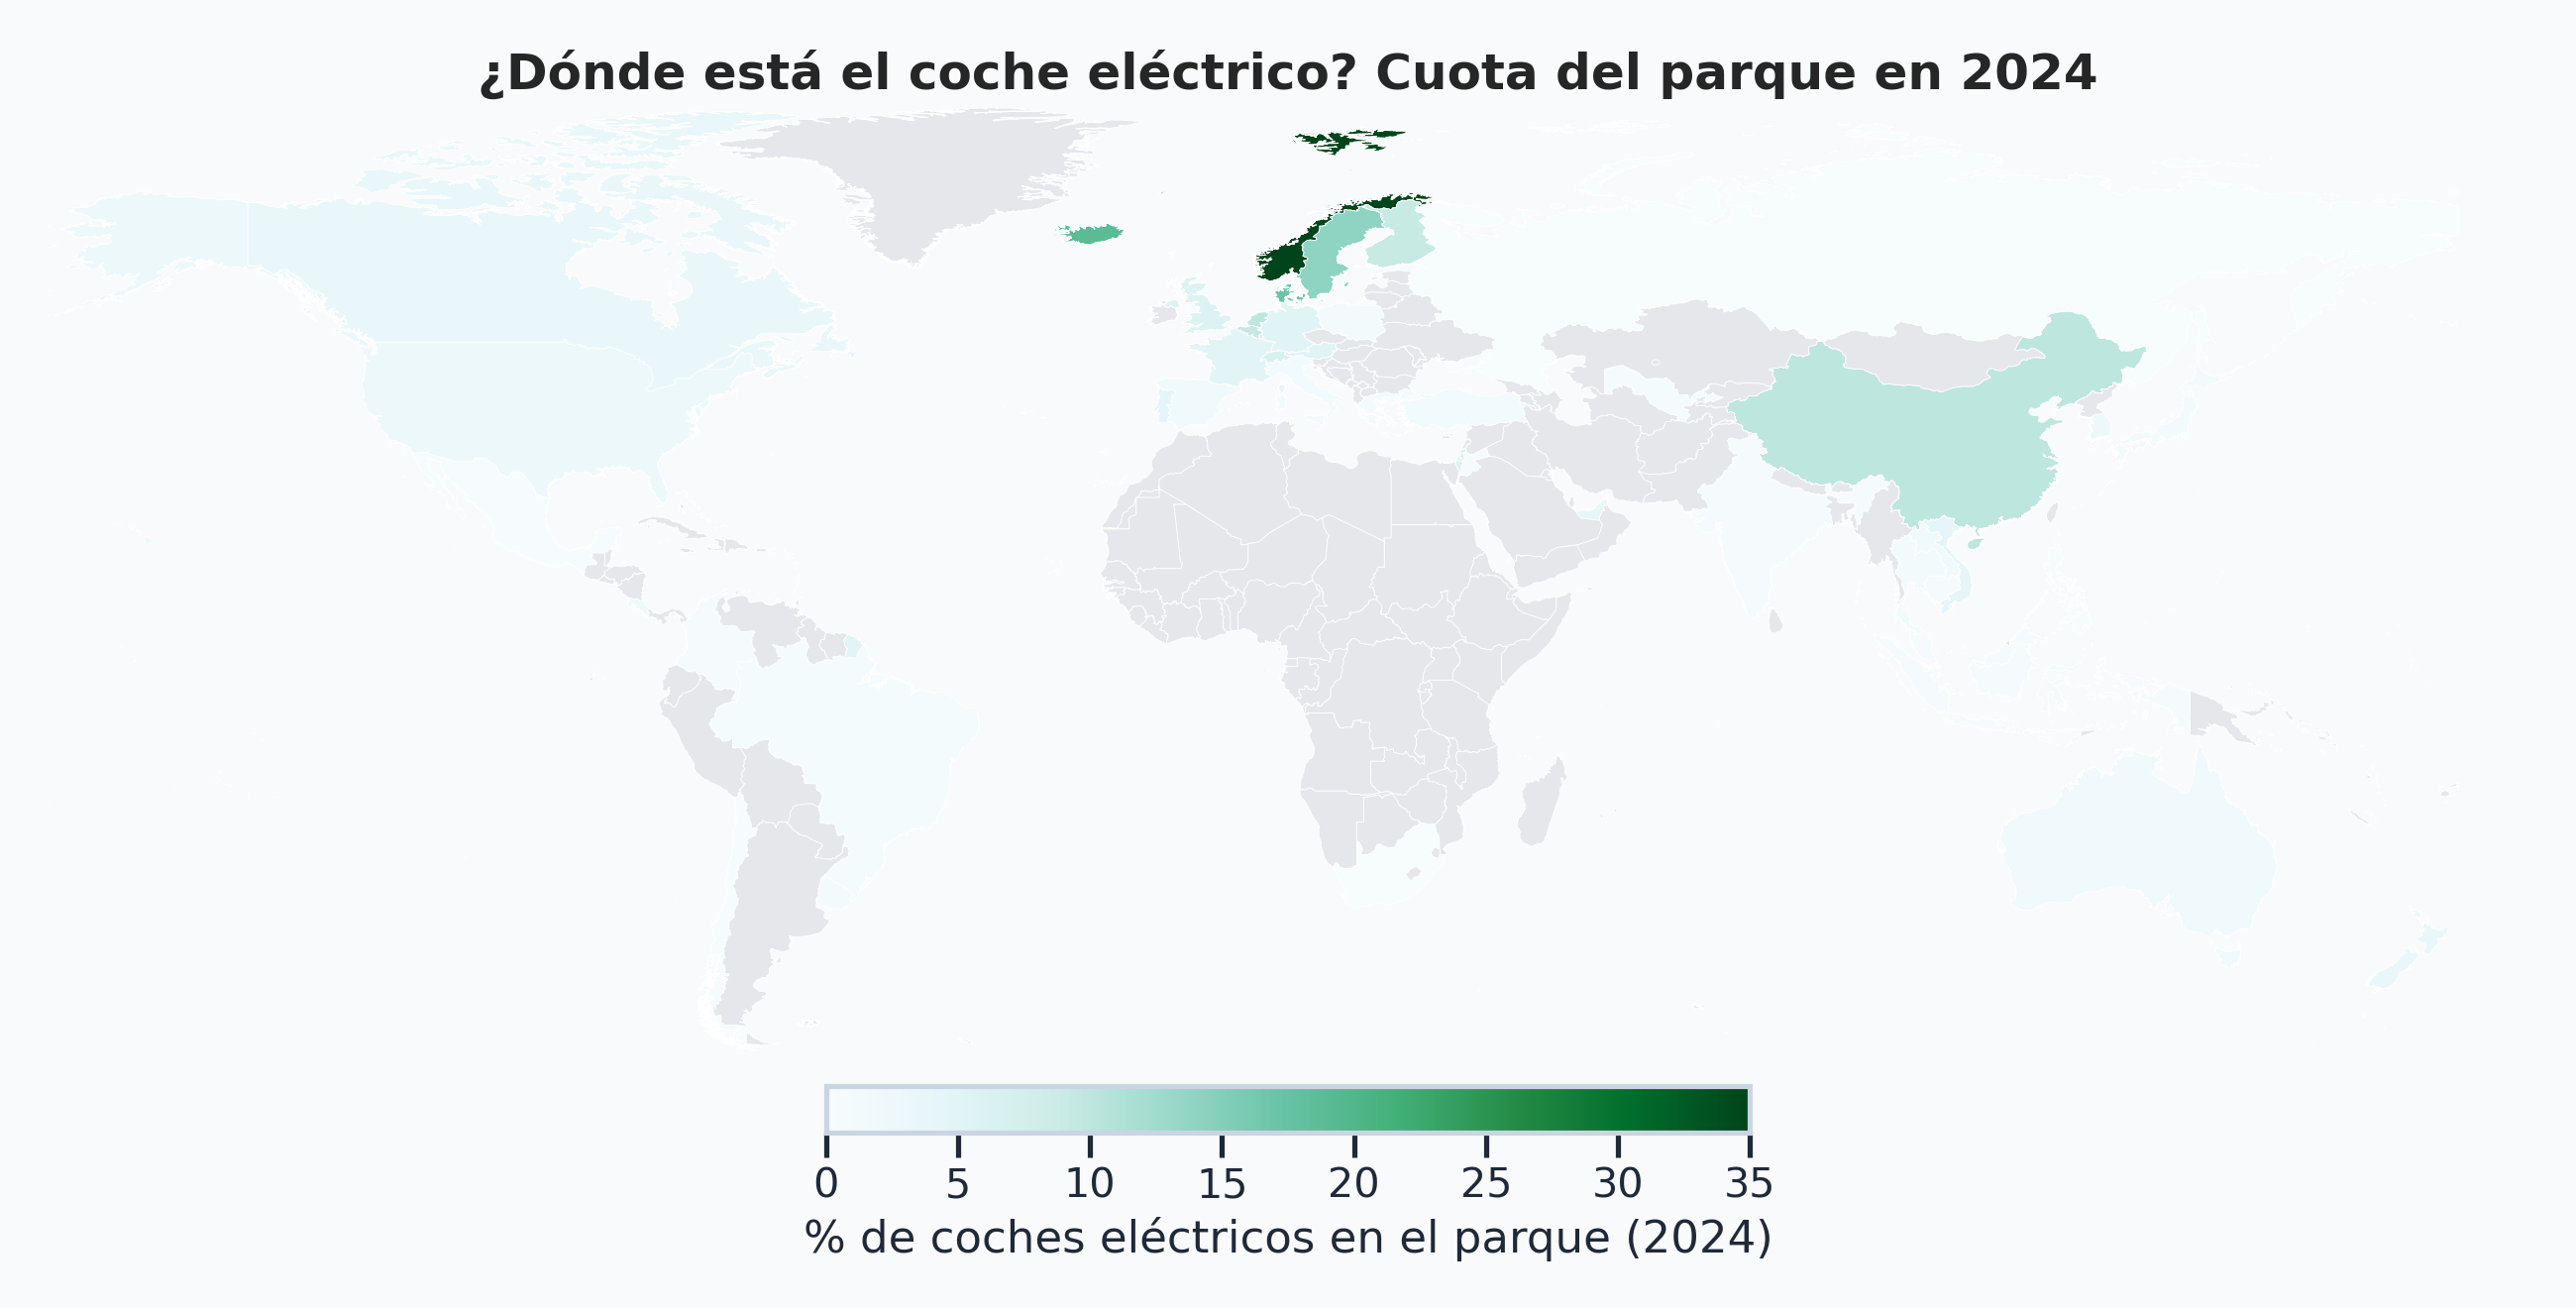

In [4]:
figuras = sorted(PRESENTACION.glob("0[12]_*.png"))
for f in figuras:
    print(f.name)
    display(Image(filename=str(f), width=800))


Lo que más me llamó la atención fue la diferencia entre países. Noruega llega al 35 % de su parque, mientras que España está en el 1,8 %. Esa diferencia tan grande es la que motiva el resto del estudio: quería saber si esa adopción desigual se nota en el CO₂ y en el aire.

## 4. Cómo leo los resultados

Cada hipótesis se contrasta con una **regresión lineal**. Una regresión resume la relación entre dos variables con dos números clave:

- **La pendiente**: cuánto cambia la variable de resultado cuando la variable explicativa sube una unidad.
- **El valor p**: si la pendiente es compatible con cero. Uso el umbral habitual de 0,05.

Para calcular los errores de estas pendientes usé el método **HC3**. La memoria explica por qué: con 43 a 46 países, los errores clásicos no tienen garantías, y el contraste de Breusch-Pagan rechaza que la dispersión sea constante en H1 con renta y en H2. Los errores clásicos y HC1 los uso solo como sensibilidad.

Cargo la tabla con los resultados del estimador principal.


In [5]:
comp = pd.read_csv(TABLAS / "comparacion_estimadores.csv")
principal = comp[comp["estimador"] == "HC3"][["hipotesis", "modelo", "n", "variable", "coef", "p", "ic95_lo", "ic95_hi", "R2"]]
display(principal.round(3).reset_index(drop=True))


,hipotesis,modelo,n,variable,coef,p,ic95_lo,ic95_hi,R2
0,H1,sin controles,46,cuota_2023,-1.471,0.106,-3.255,0.312,0.132
1,H1,con renta,46,cuota_2023,-0.368,0.290,-1.049,0.314,0.333
2,H2,sin controles,43,puntos_por_1000_hab,1.715,0.021,0.261,3.169,0.439
3,H2,con renta,43,puntos_por_1000_hab,1.383,0.057,-0.043,2.810,0.489
4,H2,con los tres controles,43,puntos_por_1000_hab,1.441,0.034,0.109,2.772,0.532
5,H3,simple,46,cuota_parque_pct,-0.319,0.032,-0.610,-0.027,0.078
6,H3,con renta,46,cuota_parque_pct,-0.189,0.113,-0.424,0.045,0.111
7,H3,con urbanización y densidad,46,cuota_parque_pct,-0.280,0.195,-0.703,0.143,0.192
8,H3,con los tres controles,46,cuota_parque_pct,-0.053,0.724,-0.345,0.240,0.304


## 5. Hipótesis 1 · CO₂ del transporte

**Qué quería comprobar.** Que los países con más coches eléctricos en 2023 hayan reducido más su CO₂ del transporte por persona entre 2015 y 2023.

**Primer resultado, sin controles.** La pendiente es −1,47: por cada punto más de cuota eléctrica, el cambio de CO₂ por persona baja de media 1,47 puntos. Pero el valor p es 0,106, así que no puedo descartar que sea casualidad. El intervalo va de −3,25 a 0,31 y contiene el cero.

**Qué pasó al añadir la renta.** La pendiente baja a −0,37 (p = 0,290): casi desaparece. En cambio, el efecto de la renta sí es claro (p = 0,002). El R² sube de 0,13 a 0,33, es decir, la renta explica bastante más que la cuota.

**Por qué cambió.** Los países ricos tienen más coches eléctricos y, además, han reducido más su CO₂ por motivos que no medimos. Cuando comparo países igual de ricos, la diferencia asociada al coche eléctrico se hace pequeña.

**Lo que sí encontré.** La correlación de Spearman es negativa (ρ = −0,45, p = 0,002): los países con más coches eléctricos tienden a estar más abajo en CO₂, en orden. Eso es una asociación, no un efecto lineal demostrado.

**Lo que puedo concluir y lo que no.** Puedo decir que hay una asociación negativa, pero que la riqueza pesa más y que la pendiente lineal no es firme. No puedo afirmar que el coche eléctrico, por sí solo, reduzca el CO₂.

Este es el gráfico comparativo que hice para ver el cambio de pendiente. Las dos rectas se cruzan en el centro de los datos: la diferencia entre ellas es solo la inclinación.


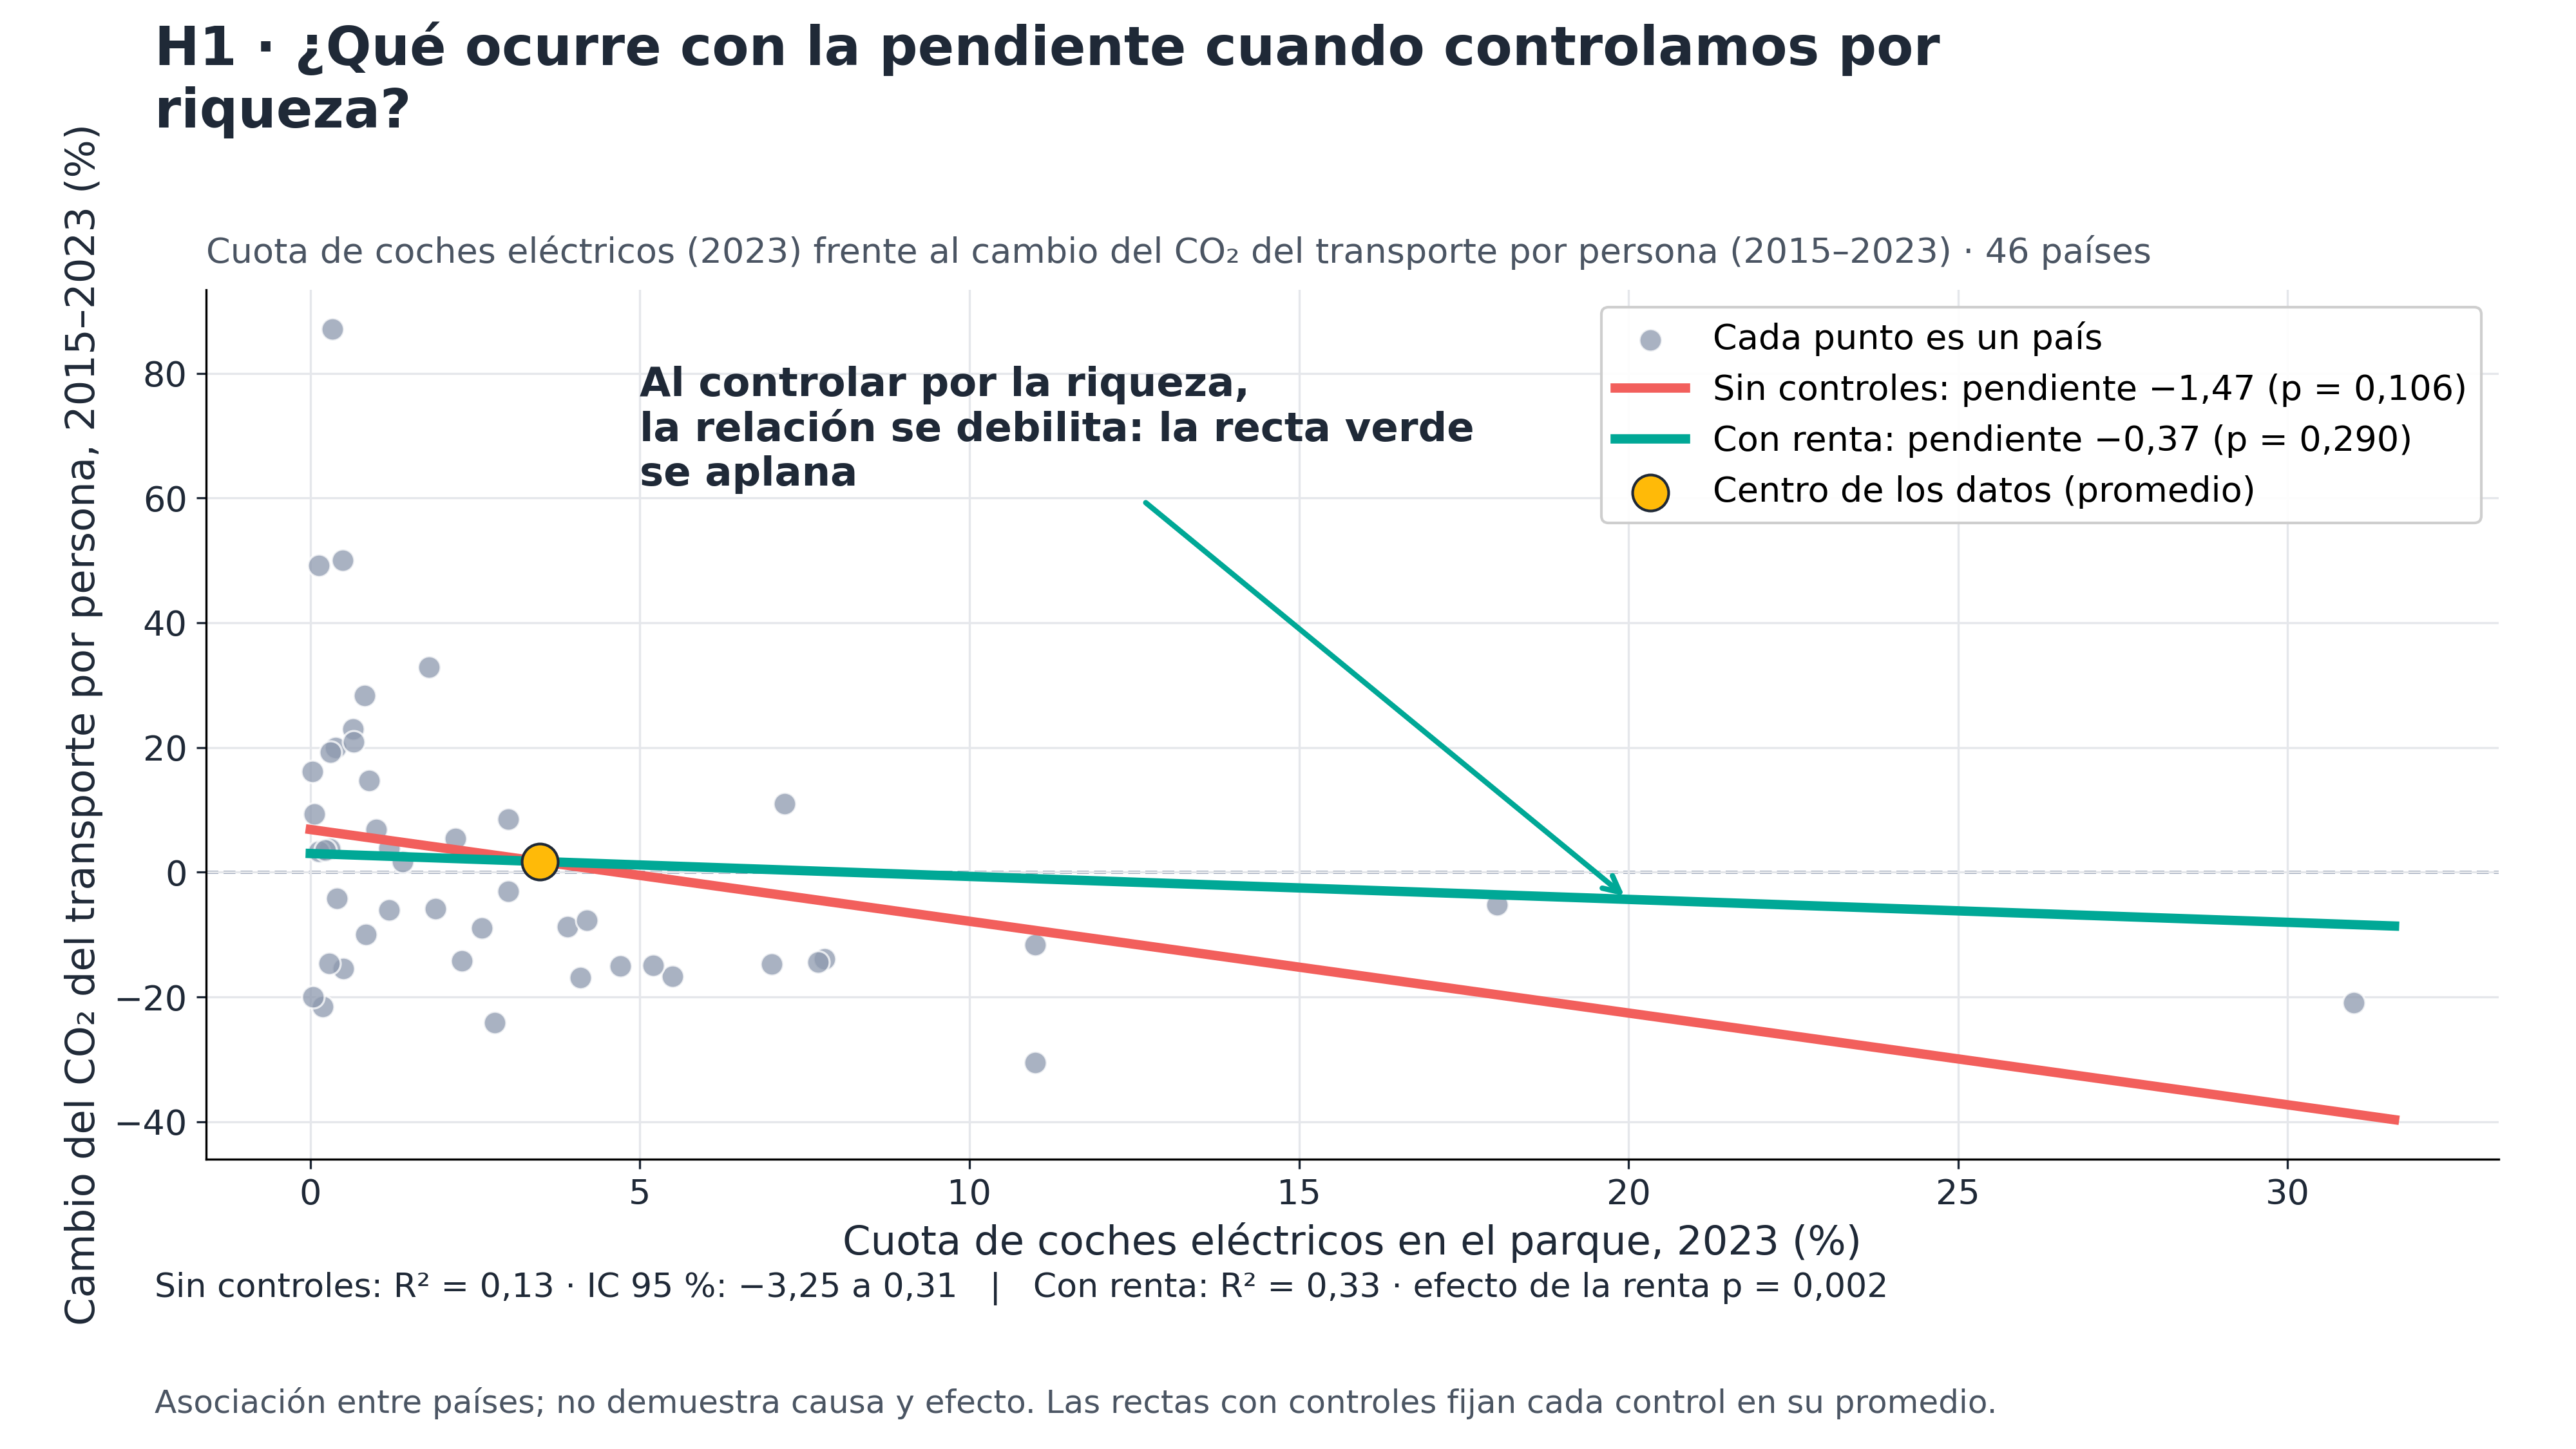

In [6]:
display(Image(filename=str(GRAFICOS / "H1_pendiente_sin_y_con_renta.png"), width=1000))


## 6. Hipótesis 2 · Infraestructura de recarga

**Qué quería comprobar.** Que los países con más puntos de recarga públicos por habitante tengan más coches eléctricos en su parque en 2024.

**La relación general.** La correlación de Pearson es r = 0,66 (IC 95 %: 0,51 a 0,91) con 43 países. Es una relación fuerte. La de Spearman es ρ = 0,85: el orden de los países se parece mucho al de la cuota, así que no depende solo de unos pocos valores extremos. El intervalo lo calculé por bootstrap, remuestreando los países 5.000 veces con semilla fija.

**Pendiente sin controles.** 1,71 puntos de cuota por cada punto de recarga por 1.000 habitantes, con p = 0,021.

**Pendiente con tres controles.** Al controlar por renta, urbanización y densidad, la pendiente es 1,44, con p = 0,034 e intervalo de 0,11 a 2,77. El R² es 0,53. Es decir: a igualdad de esos tres factores, la relación se mantiene.

**Lo que me preocupa.** Con la renta sola, la pendiente pasa a 1,38 con p = 0,057, justo por encima de 0,05. Y el resultado con tres controles depende de algunos países: al quitar Bélgica, Islandia, Corea del Sur o Países Bajos, el p sube por encima de 0,05. Lo presento como una relación sólida pero no firme.

**Por qué no es causa y efecto.** Puede que los cargadores favorezcan la compra, que la demanda de coches eléctricos traiga más cargadores, o que la riqueza de un país empuje las dos cosas. Los datos no distinguen entre estas explicaciones.

Gráfico comparativo de H2: la pendiente baja de 1,71 a 1,44, pero se mantiene positiva.


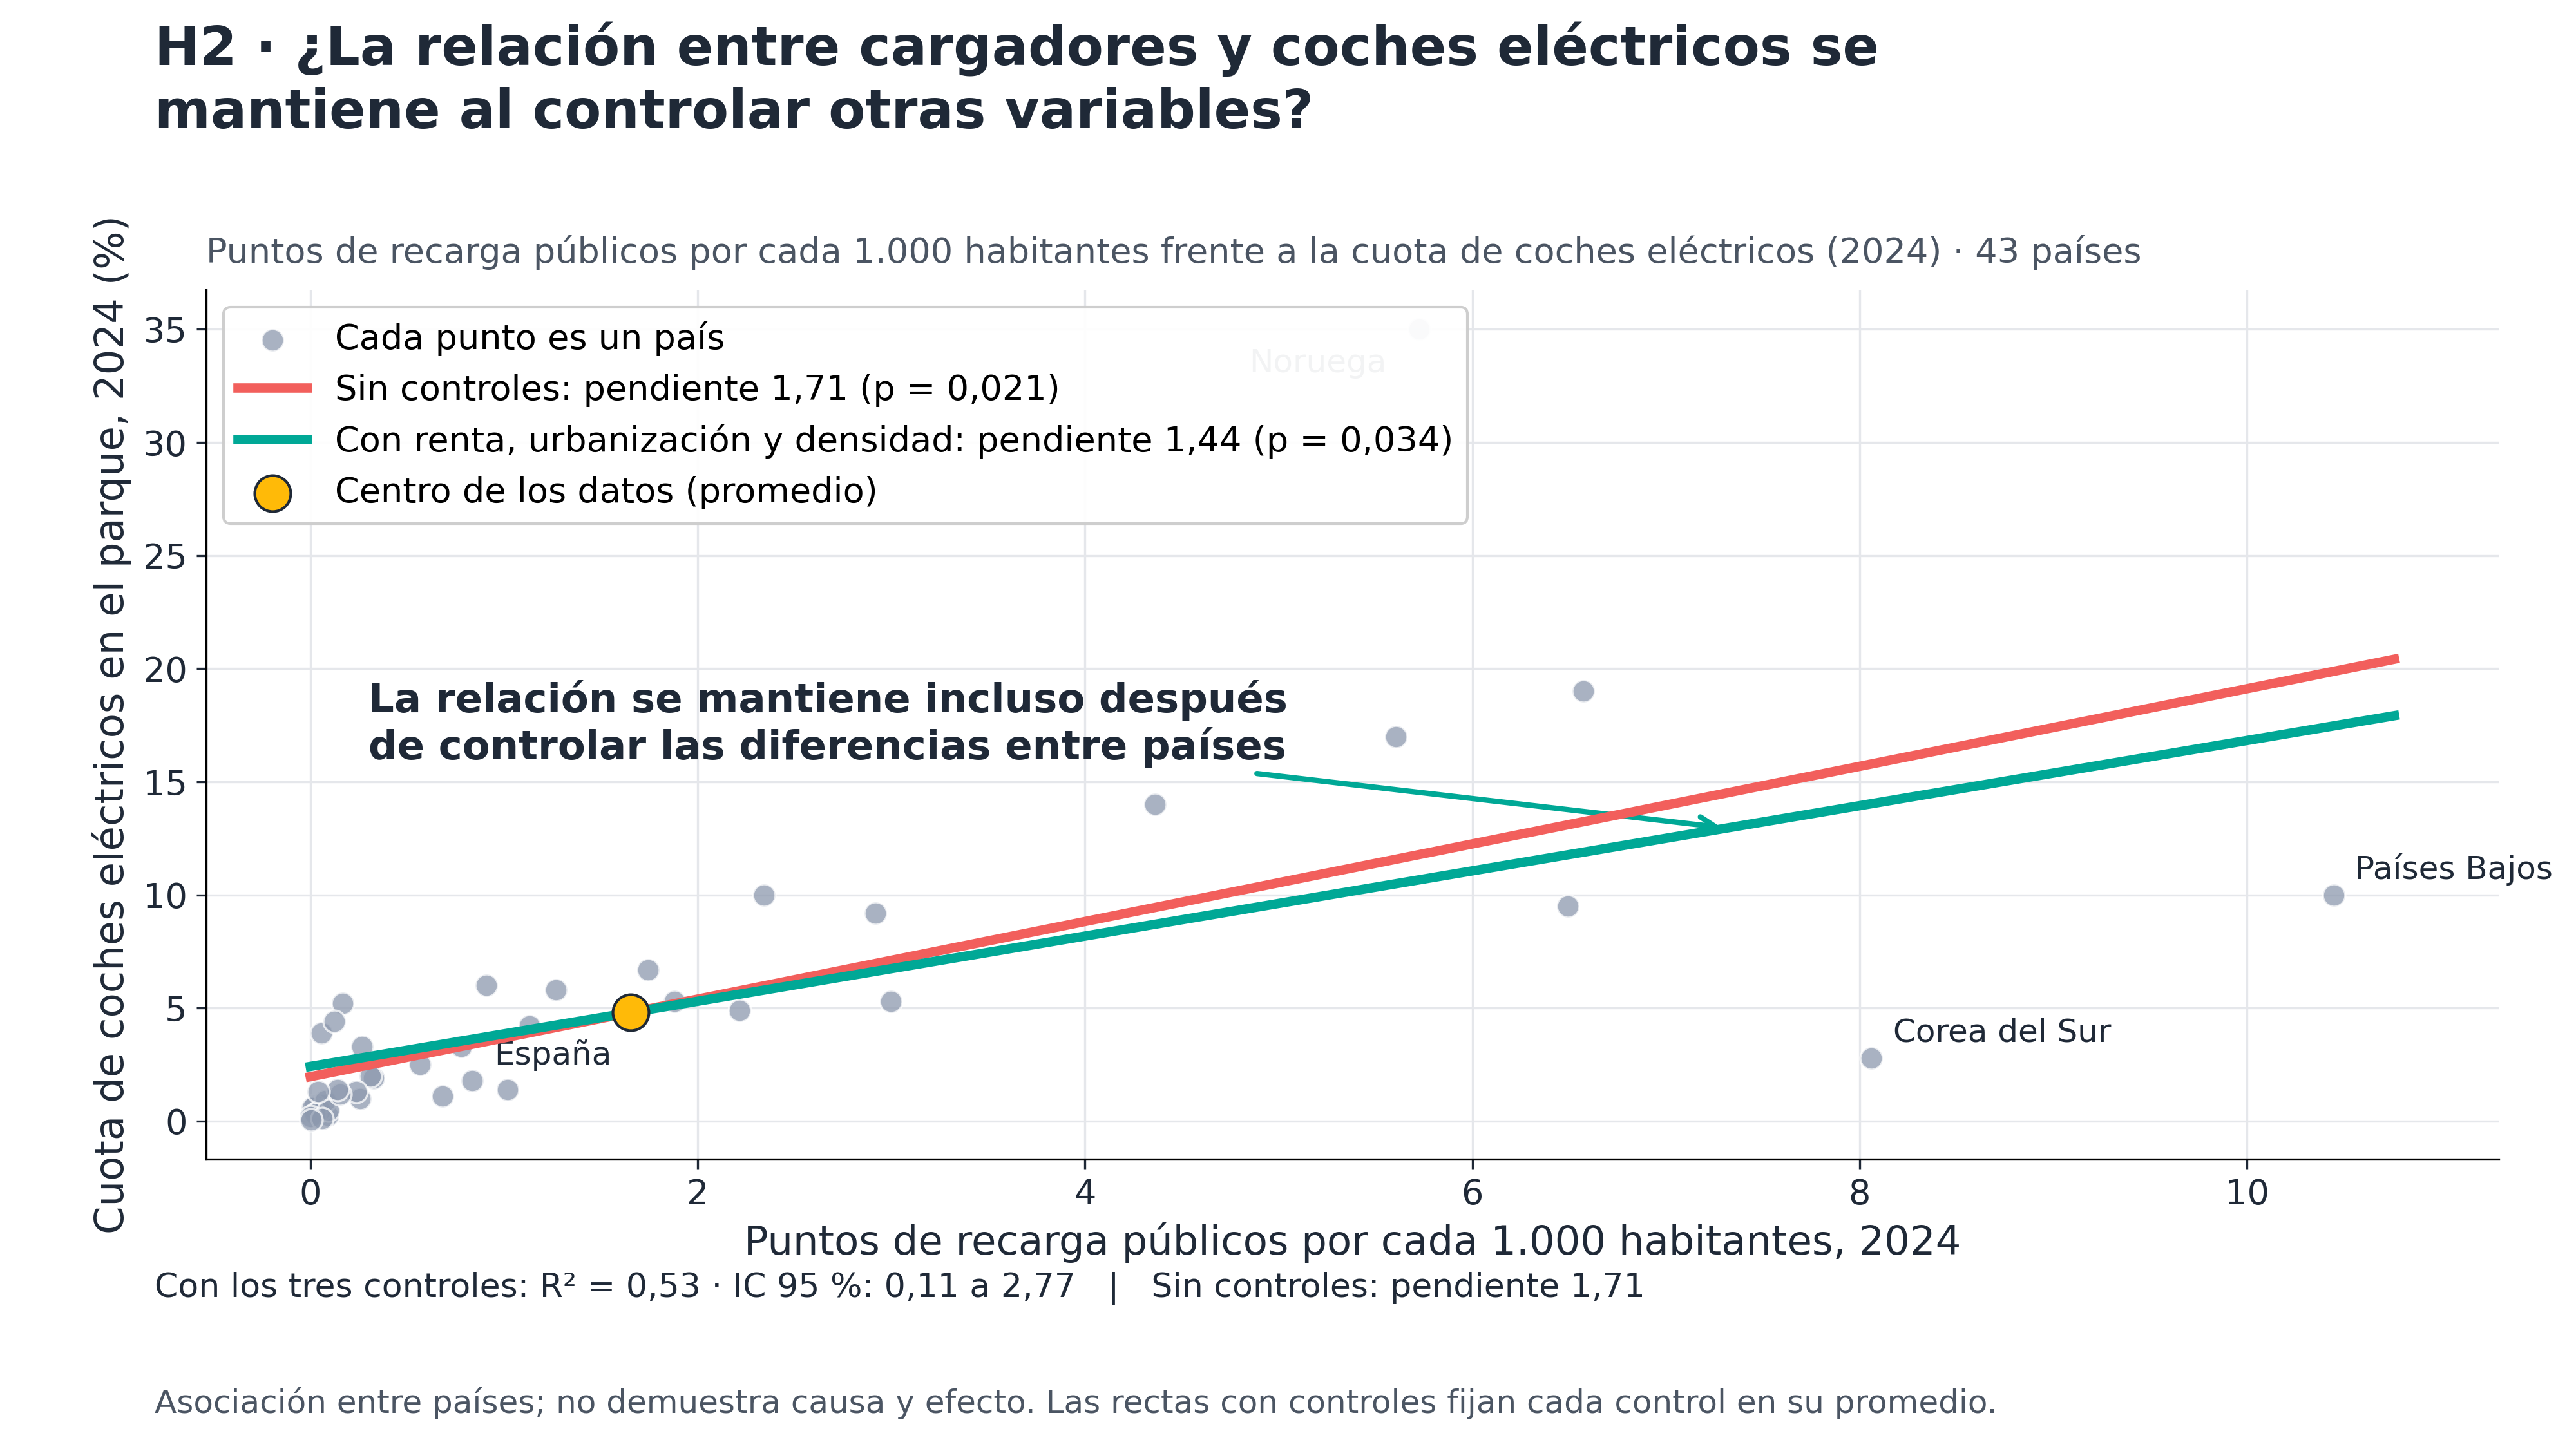

In [7]:
display(Image(filename=str(GRAFICOS / "H2_pendiente_sin_y_con_controles.png"), width=1000))


## 7. Hipótesis 3 · Contaminación urbana (NO₂)

**Qué quería comprobar.** Que los países con más coches eléctricos en 2024 tengan menos NO₂ estimado en sus áreas urbanas entre abril y noviembre de 2025.

**Primer resultado.** Sin controles, la pendiente es −0,32 con p = 0,032 (método principal). La correlación de Pearson, que es un contraste complementario, da r = −0,28 con p = 0,061. Es decir, la señal inicial es débil y depende del método.

**Con renta.** La pendiente baja a −0,19 con p = 0,113. Ya no se distingue de cero.

**Con renta, urbanización y densidad.** La pendiente es −0,05 con p = 0,724 y el R² sube a 0,30. Prácticamente desaparece.

**Por qué cambia.** La renta se mueve a la vez con las dos variables: los países ricos tienen más coches eléctricos y también un NO₂ más bajo. Al comparar países igual de ricos, urbanos y densos, la cuota eléctrica deja de aportar información distinta.

**Limitaciones que tengo que decir.** El NO₂ es un valor estimado por un modelo, y la unidad no está documentada en la fuente, así que no la atribuyo. Solo cubre abril a noviembre de 2025. Y el tráfico de cada ciudad importa mucho, pero no lo medí.

**Lo que no significa.** No significa que el coche eléctrico no reduzca la contaminación de su propio motor. Significa que entre estos países no encuentro una relación independiente con el aire urbano una vez tenidos en cuenta otros factores.

Gráfico comparativo de H3: con cada control, la pendiente se acerca a cero.


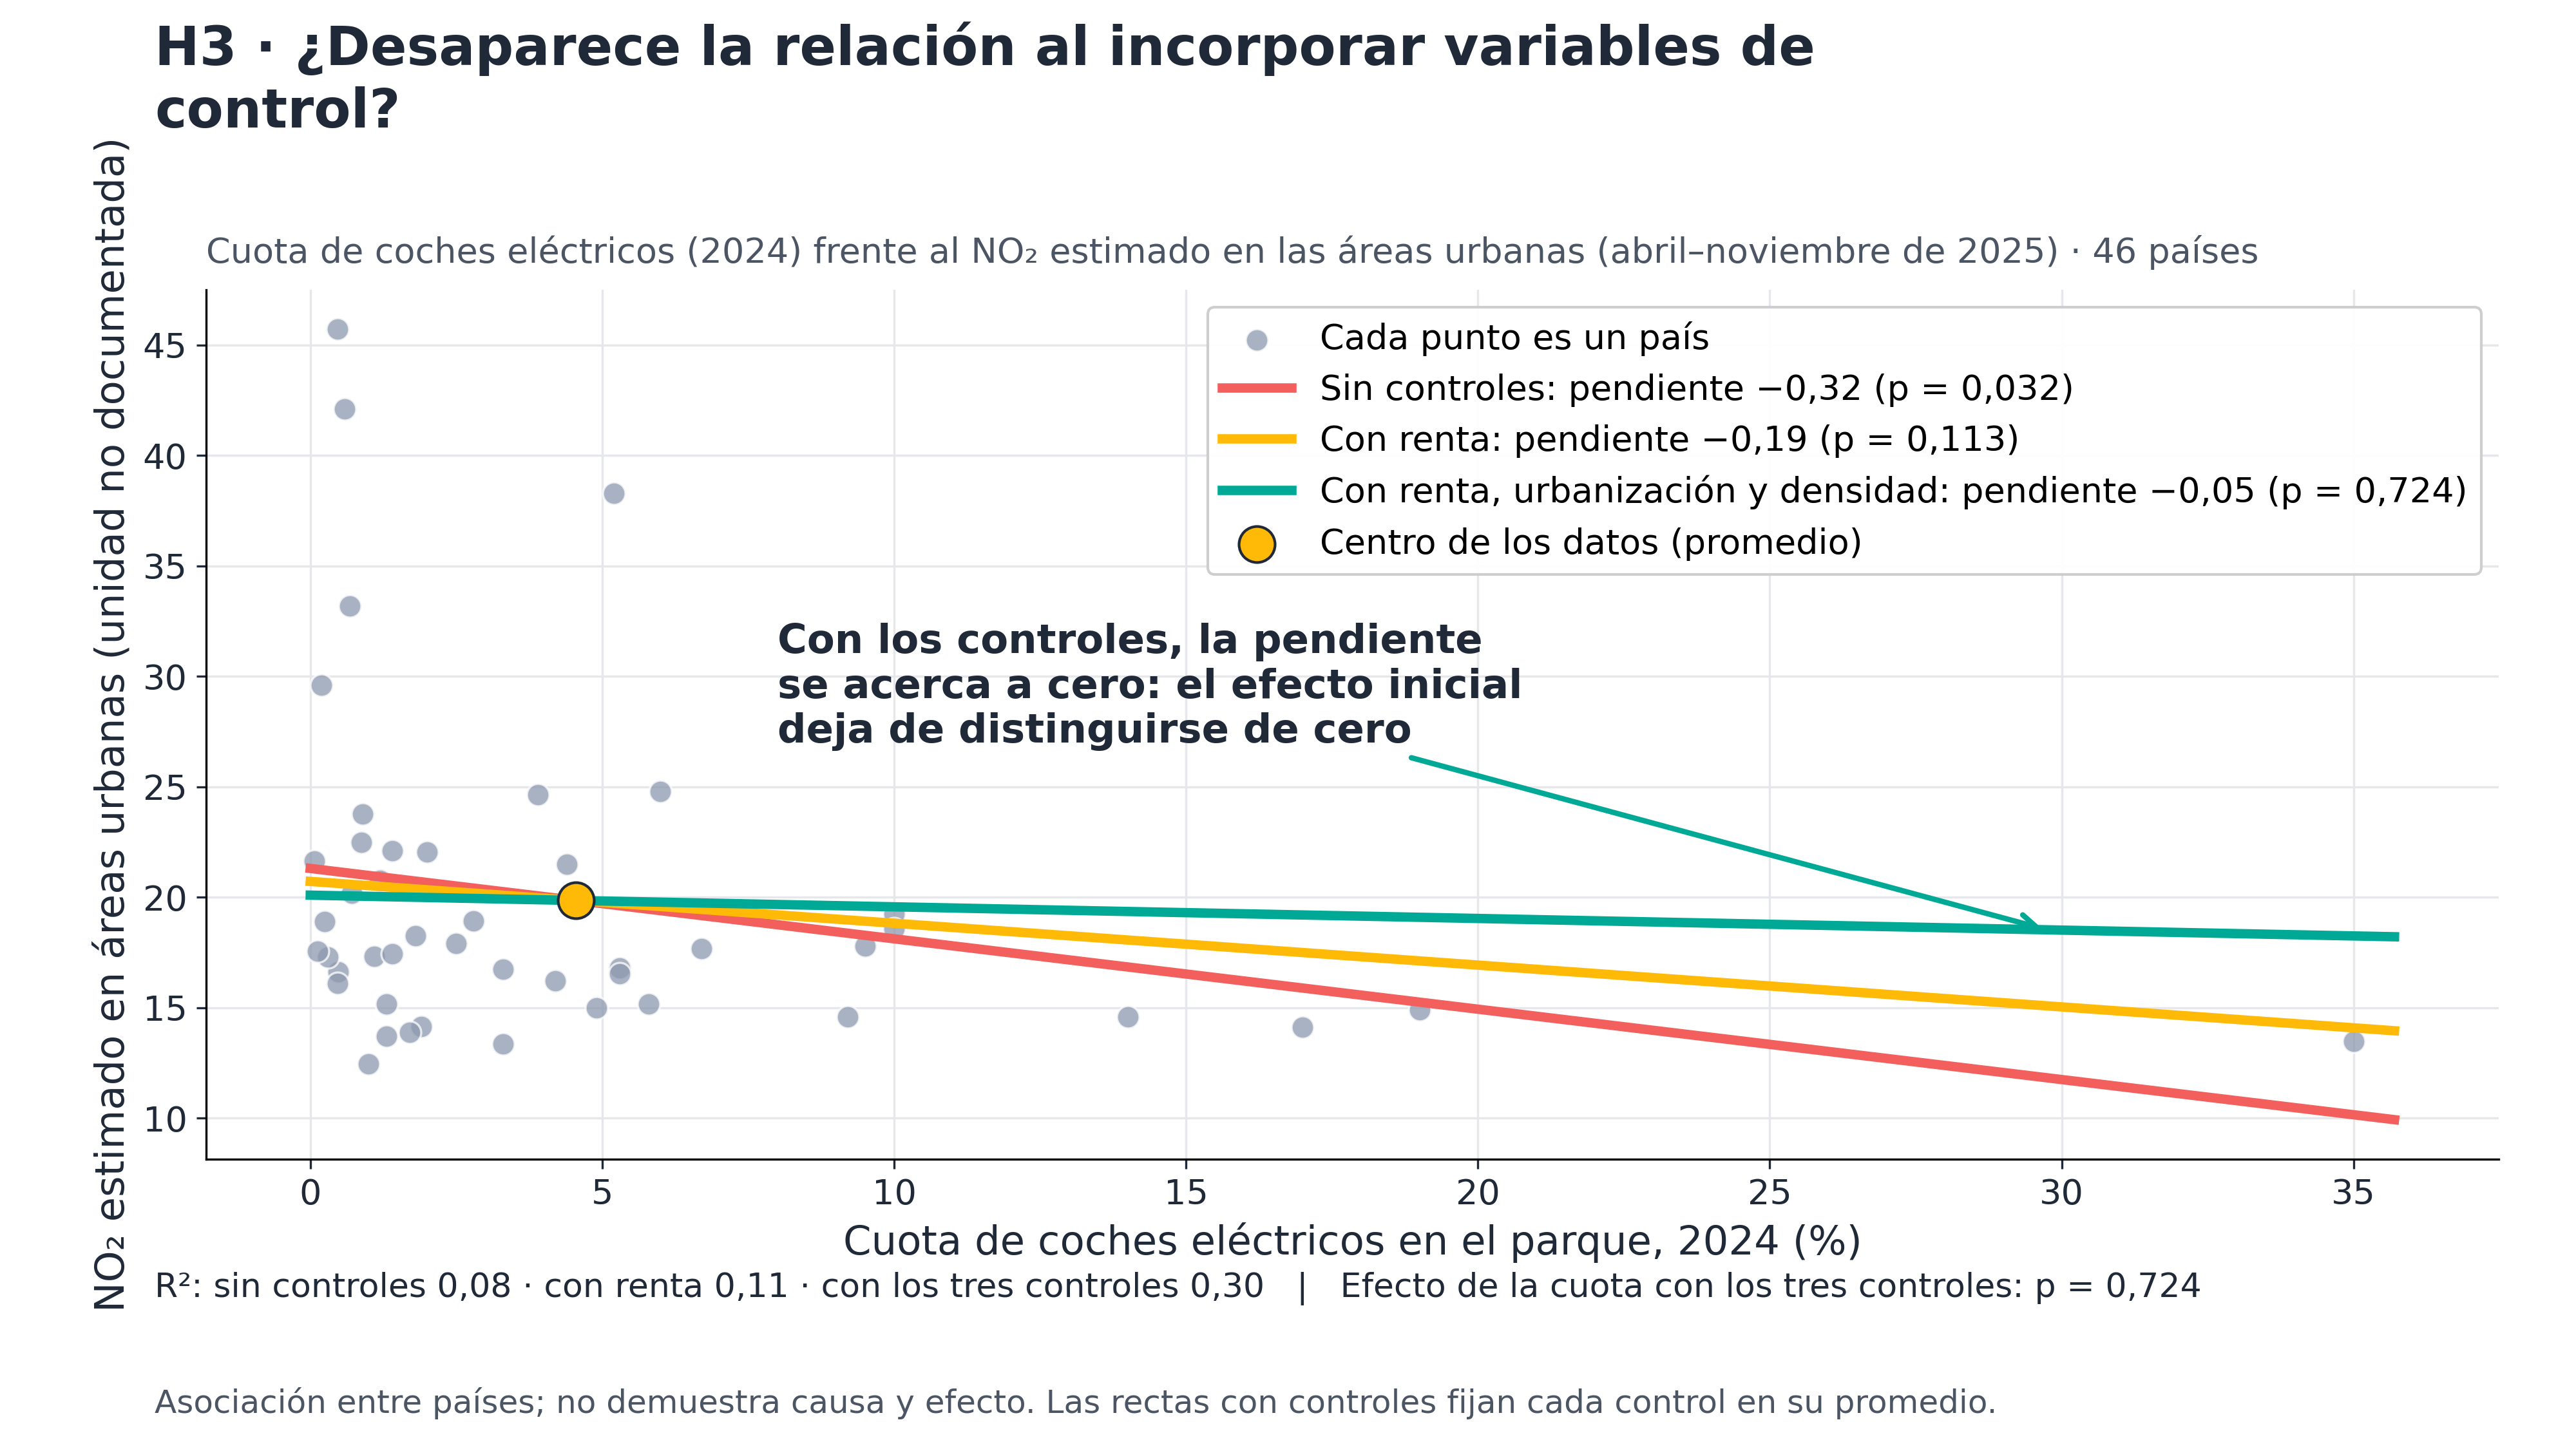

In [8]:
display(Image(filename=str(GRAFICOS / "H3_pendiente_sin_y_con_controles.png"), width=1000))


## 8. Comparación final de las tres hipótesis

Una última comprobación: cómo se comparan las correlaciones de Pearson y Spearman de cada hipótesis.


In [9]:
corr = pd.read_csv(TABLAS / "correlaciones.csv")
display(corr.round(3))


,hipotesis,n,pearson_r,pearson_t,pearson_p,spearman_rho,spearman_p
0,H1,46,-0.364,-2.590,0.013,-0.449,0.002
1,H2,43,0.662,5.661,0.000,0.853,0.000
2,H3,46,-0.278,-1.923,0.061,-0.338,0.022


En resumen:

- **H2** es la relación más sólida del estudio, aunque depende de algunos países y del método.
- **H1** muestra una asociación negativa en orden, pero la pendiente no es firme y la riqueza pesa más.
- **H3** es una asociación débil que desaparece al tener en cuenta otros factores.

Ninguna de las tres sobrevive a la corrección de Holm por hacer varias pruebas a la vez; la memoria lo recoge expresamente y lo presento como indicios, no como efectos demostrados.

## 9. Conclusiones personales

Lo que más aprendí en este estudio es que **una correlación inicial no demuestra causalidad**. En los tres casos, la relación que veía al principio cambiaba al tener en cuenta otros factores. Eso me enseñó que hay que preguntarse siempre qué otra cosa puede estar detrás.

También aprendí que **asociación y efecto independiente son cosas distintas**. Un coeficiente grande puede desaparecer al controlar, y eso no es un fallo: es información sobre cómo se relacionan las variables.

Por último, me quedo con que **los resultados no siempre coinciden con lo que uno espera**. La hipótesis H3 proponía que el coche eléctrico se vería en el aire de las ciudades, y en estos datos esa relación no se sostiene al controlar.

## 10. Limitaciones

- **Son datos entre países**, no entre ciudades. Una media nacional no describe lo que pasa en cada ciudad.
- **Hay datos que faltan.** Cada análisis usa 43 o 46 países, no los 61.
- **El NO₂ es estimado** y solo cubre abril–noviembre de 2025, sin invierno.
- **Los periodos no coinciden**: cuota de 2023 y 2024, NO₂ de 2025, CO₂ de 2015–2023.
- **Un país puede mover la línea.** Noruega es el caso extremo en varias hipótesis.
- **No hay diseño causal.** Para demostrar causa haría falta seguir zonas concretas en el tiempo, algo que estos datos no permiten.

